In [1]:
import spatialdata as sd
import decoupler as dc
from spatialdata_io import xenium

import numpy as np
import pandas as pd
import scipy.sparse as sp


import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

import scanpy as sc

import squidpy as sq

sc.set_figure_params(figsize=(12,12))
mpl.rcParams['figure.dpi'] = 300

import os

import sys
plt.style.use('default')

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
Sample_895=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_895.h5ad")
Sample_894=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_894.h5ad")
Sample_898=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_898.h5ad")


In [3]:
adata = Sample_895.concatenate(Sample_894,Sample_898)

/tmp/ipykernel_399440/1532990001.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898)


In [4]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [5]:
# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 4,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# Define your gene groups
group_A = ["Dp427c", "Dp427m", "Dp427p"]
group_B = ["Dp71_Dp40_firstexon", "Dp40"]

# Filter genes that exist in the dataset
group_A = [gene for gene in group_A if gene in adata.var_names]
group_B = [gene for gene in group_B if gene in adata.var_names]

results = []

# Loop over each region and class
for region in adata.obs["Region"].unique():
    for cell_class in adata.obs["Class"].unique():
        adata_sub = adata[(adata.obs["Region"] == region) & (adata.obs["Class"] == cell_class), :]
        if adata_sub.n_obs == 0:
            continue

        # Extract and binarize expression
        expr_A = adata_sub[:, group_A].X
        expr_B = adata_sub[:, group_B].X
        

        if not isinstance(expr_A, np.ndarray):
            expr_A = expr_A.toarray()
        if not isinstance(expr_B, np.ndarray):
            expr_B = expr_B.toarray()

        binary_A = (expr_A > 0).astype(int)
        binary_B = (expr_B > 0).astype(int)
        
        

        any_A = (binary_A.sum(axis=1) > 0)
        any_B = (binary_B.sum(axis=1) > 0)
        
        only_A = any_A & (~any_B)
        only_B = any_B & (~any_A)

        n_only_A = only_A.sum()
        n_only_B = only_B.sum()

        coexpressing_cells = any_A & any_B
        both = coexpressing_cells.sum()
        either = (any_A | any_B).sum()
        percent_coexpressed = (both / either * 100) if either > 0 else np.nan
        percent_A = (n_only_A / either * 100) if either > 0 else np.nan
        percent_B = (n_only_B / either * 100) if either > 0 else np.nan
        
        
        results.append({
            "Region": region,
            "Class": cell_class,
            "GroupA": "__".join(group_A),
            "GroupB": "__".join(group_B),
            "Coexpression_Both": both,
            "Coexpression_Either": either,
            "Only_A":n_only_A,
            "Only_B":n_only_B,
            "expressionA":any_A.sum(),
            "expressionB":any_B.sum(),
            "percent_A":percent_A,
            "percent_B":percent_B,
            "percent_coexpressed":percent_coexpressed
        })

# Convert to DataFrame
coexpr_df = pd.DataFrame(results)

# Pivot for heatmap
heatmap_data = coexpr_df.pivot_table(index=["Region"],columns=["Class"], values="Coexpression_Both")
heatmap_data = heatmap_data.reindex(index=adata.obs["Region"].astype("category").cat.categories,columns=adata.obs["Class"].astype("category").cat.categories)
heatmap_data = heatmap_data.fillna(0)
# Plot heatmap
plt.figure(figsize=(4.7, 3.5))
sns.heatmap(heatmap_data, annot=True, cmap="Purples", fmt=".0f", cbar_kws={'label': 'Number of cells'})
plt.xlabel("Cell type")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/Coexpressed_cells_boxplot.svg",format="svg",dpi=300, bbox_inches='tight')
plt.close()

In [6]:
# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 4,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


# Pivot for heatmap
heatmap_data_coexpression = coexpr_df.pivot_table(index=["Region"],columns=["Class"], values="Coexpression_Either")
heatmap_data_coexpression = heatmap_data_coexpression.reindex(index=adata.obs["Region"].astype("category").cat.categories,columns=adata.obs["Class"].astype("category").cat.categories)
heatmap_data_coexpression = heatmap_data_coexpression.fillna(0)
# Plot heatmap
plt.figure(figsize=(4.7, 3.5))
sns.heatmap(heatmap_data_coexpression, annot=True, cmap="Greens", fmt=".0f", cbar_kws={'label': 'Coexpression Percent'})
plt.xlabel("Cell type")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/DMD_positive_boxplot.svg",format="svg",dpi=300, bbox_inches='tight')
plt.close()

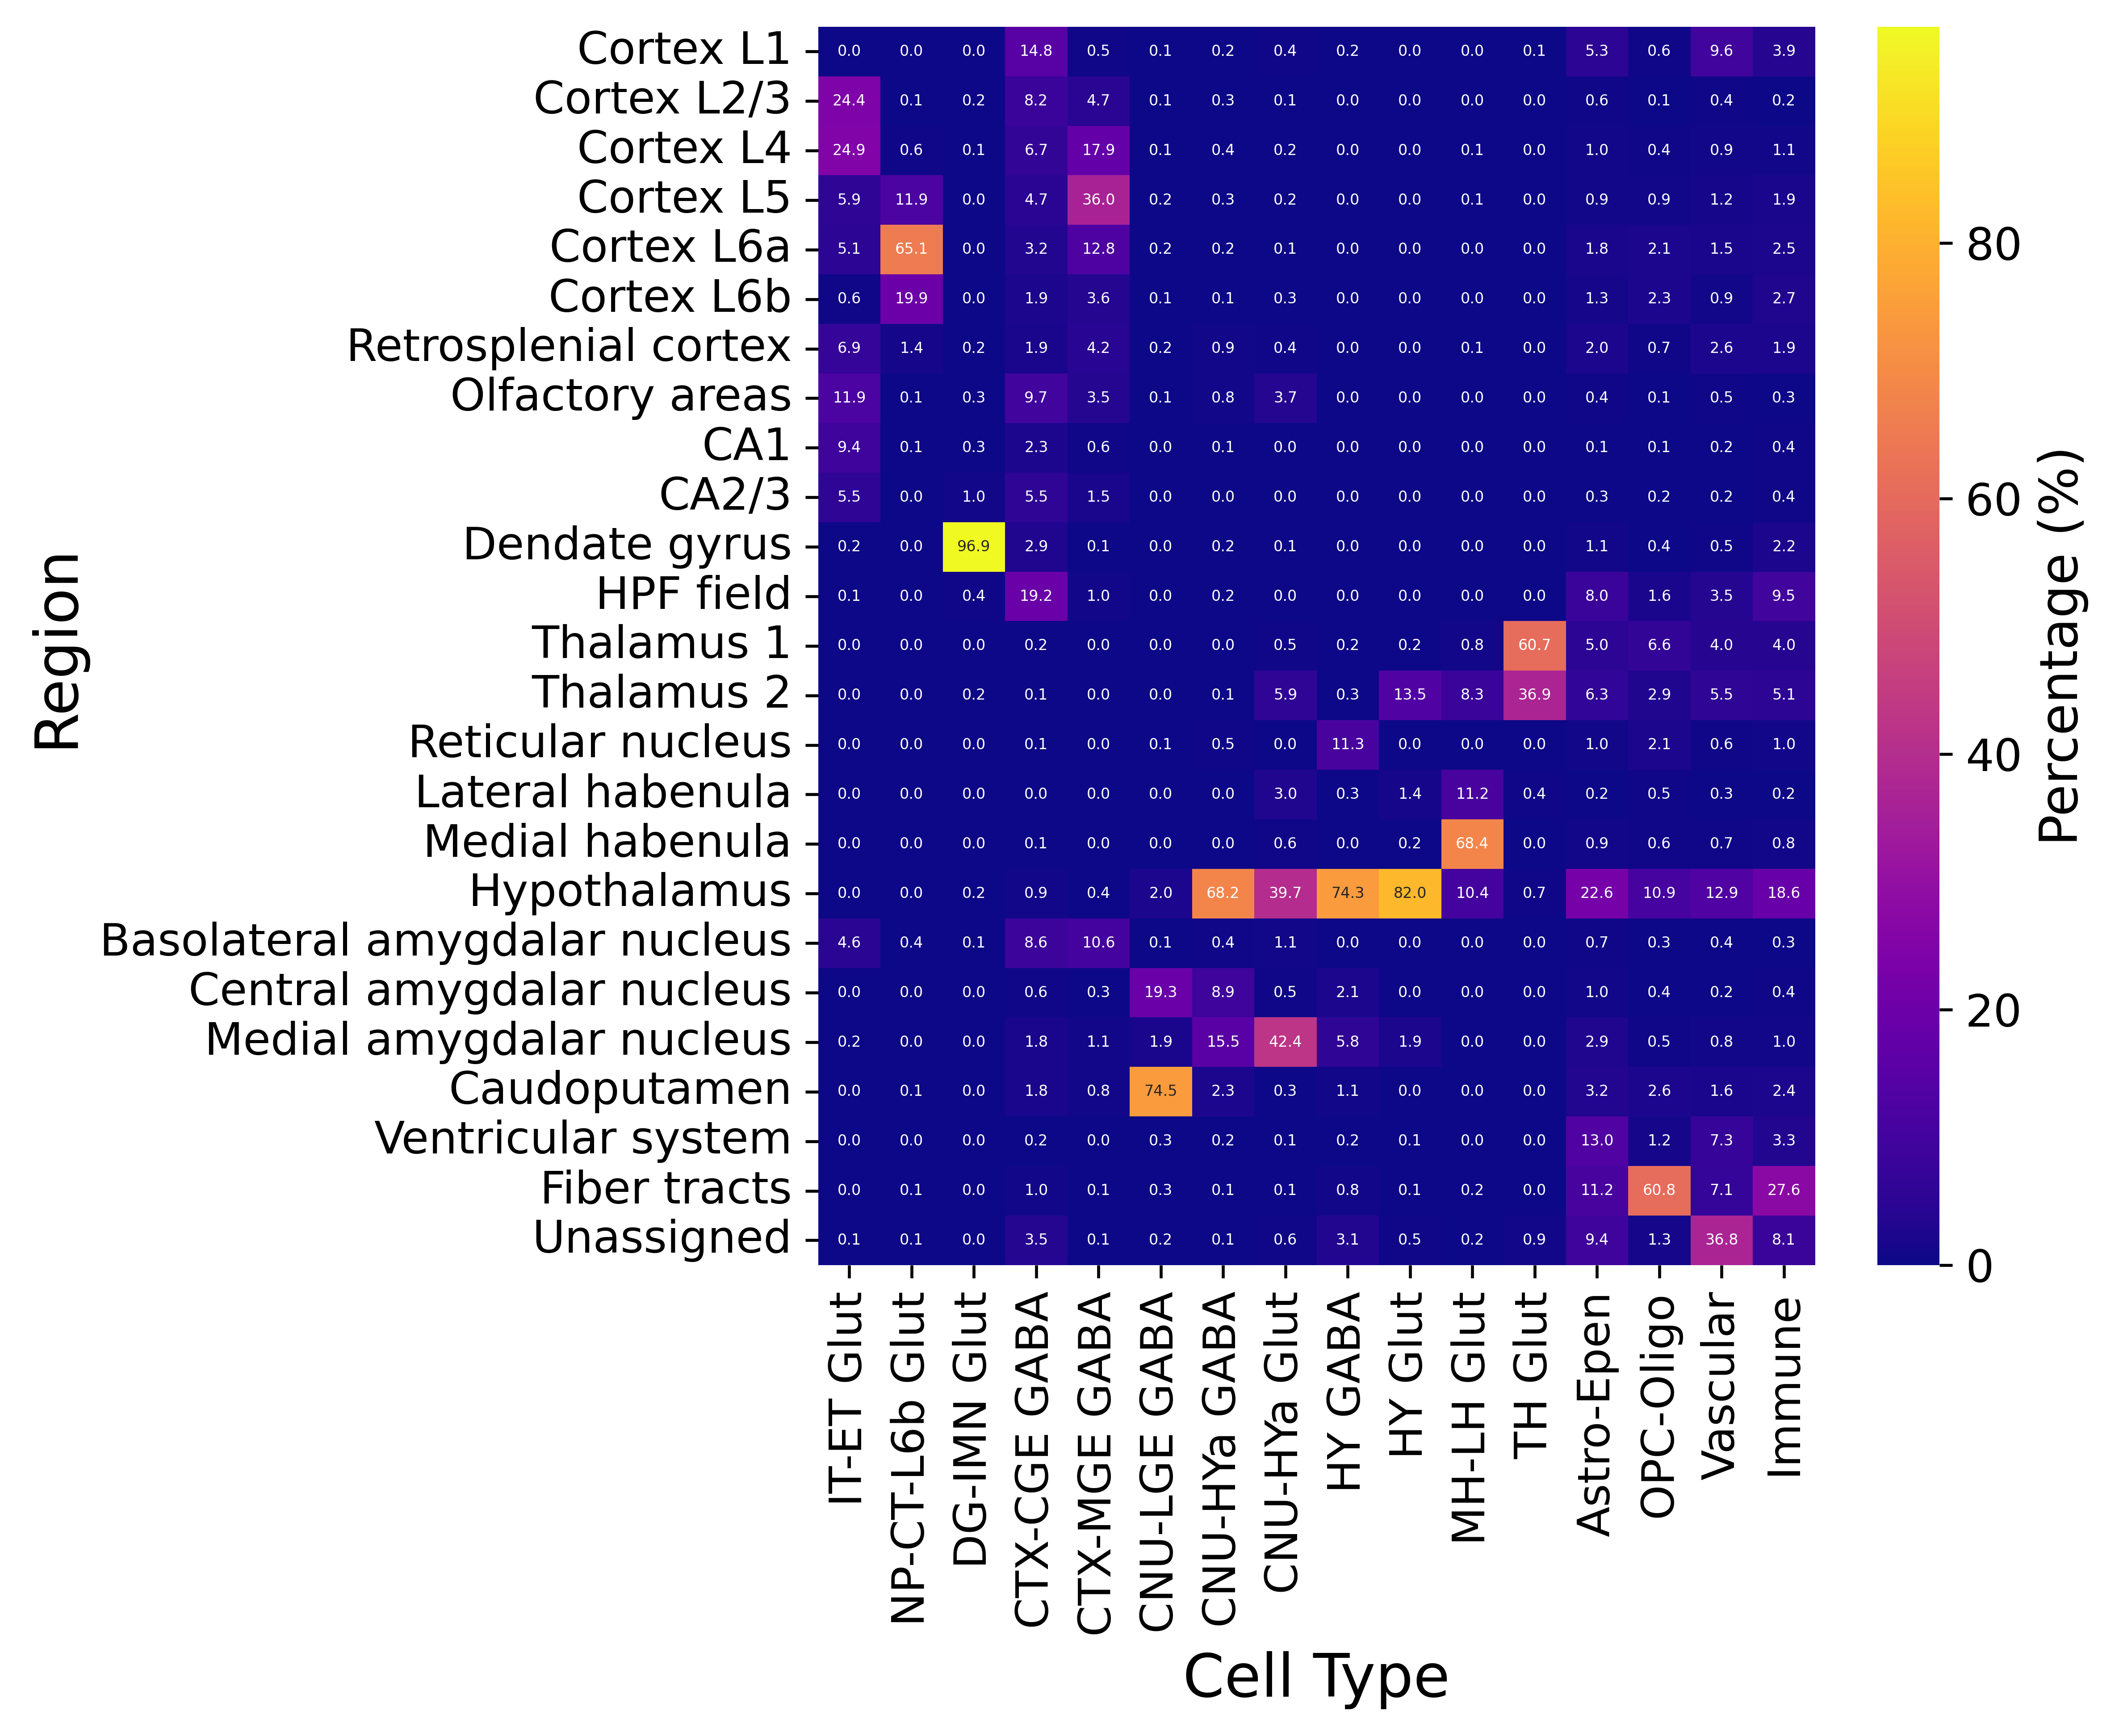

In [7]:
# Step 1: Get the count table
counts = pd.crosstab(adata.obs["Region"], adata.obs["Class"])

# Step 2: Convert to percentages (row-wise: per region)
percentages = counts.div(counts.sum(axis=0), axis=1) * 100

# Step 3: Plot as heatmap
plt.figure(figsize=(6, 6))
ax = sns.heatmap(percentages, cmap="plasma", annot=True, fmt=".1f")


ax.set_xlabel("Cell Type", fontsize=16)
ax.set_ylabel("Region", fontsize=16)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

# Make colorbar label larger
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label("Percentage (%)", fontsize=14)

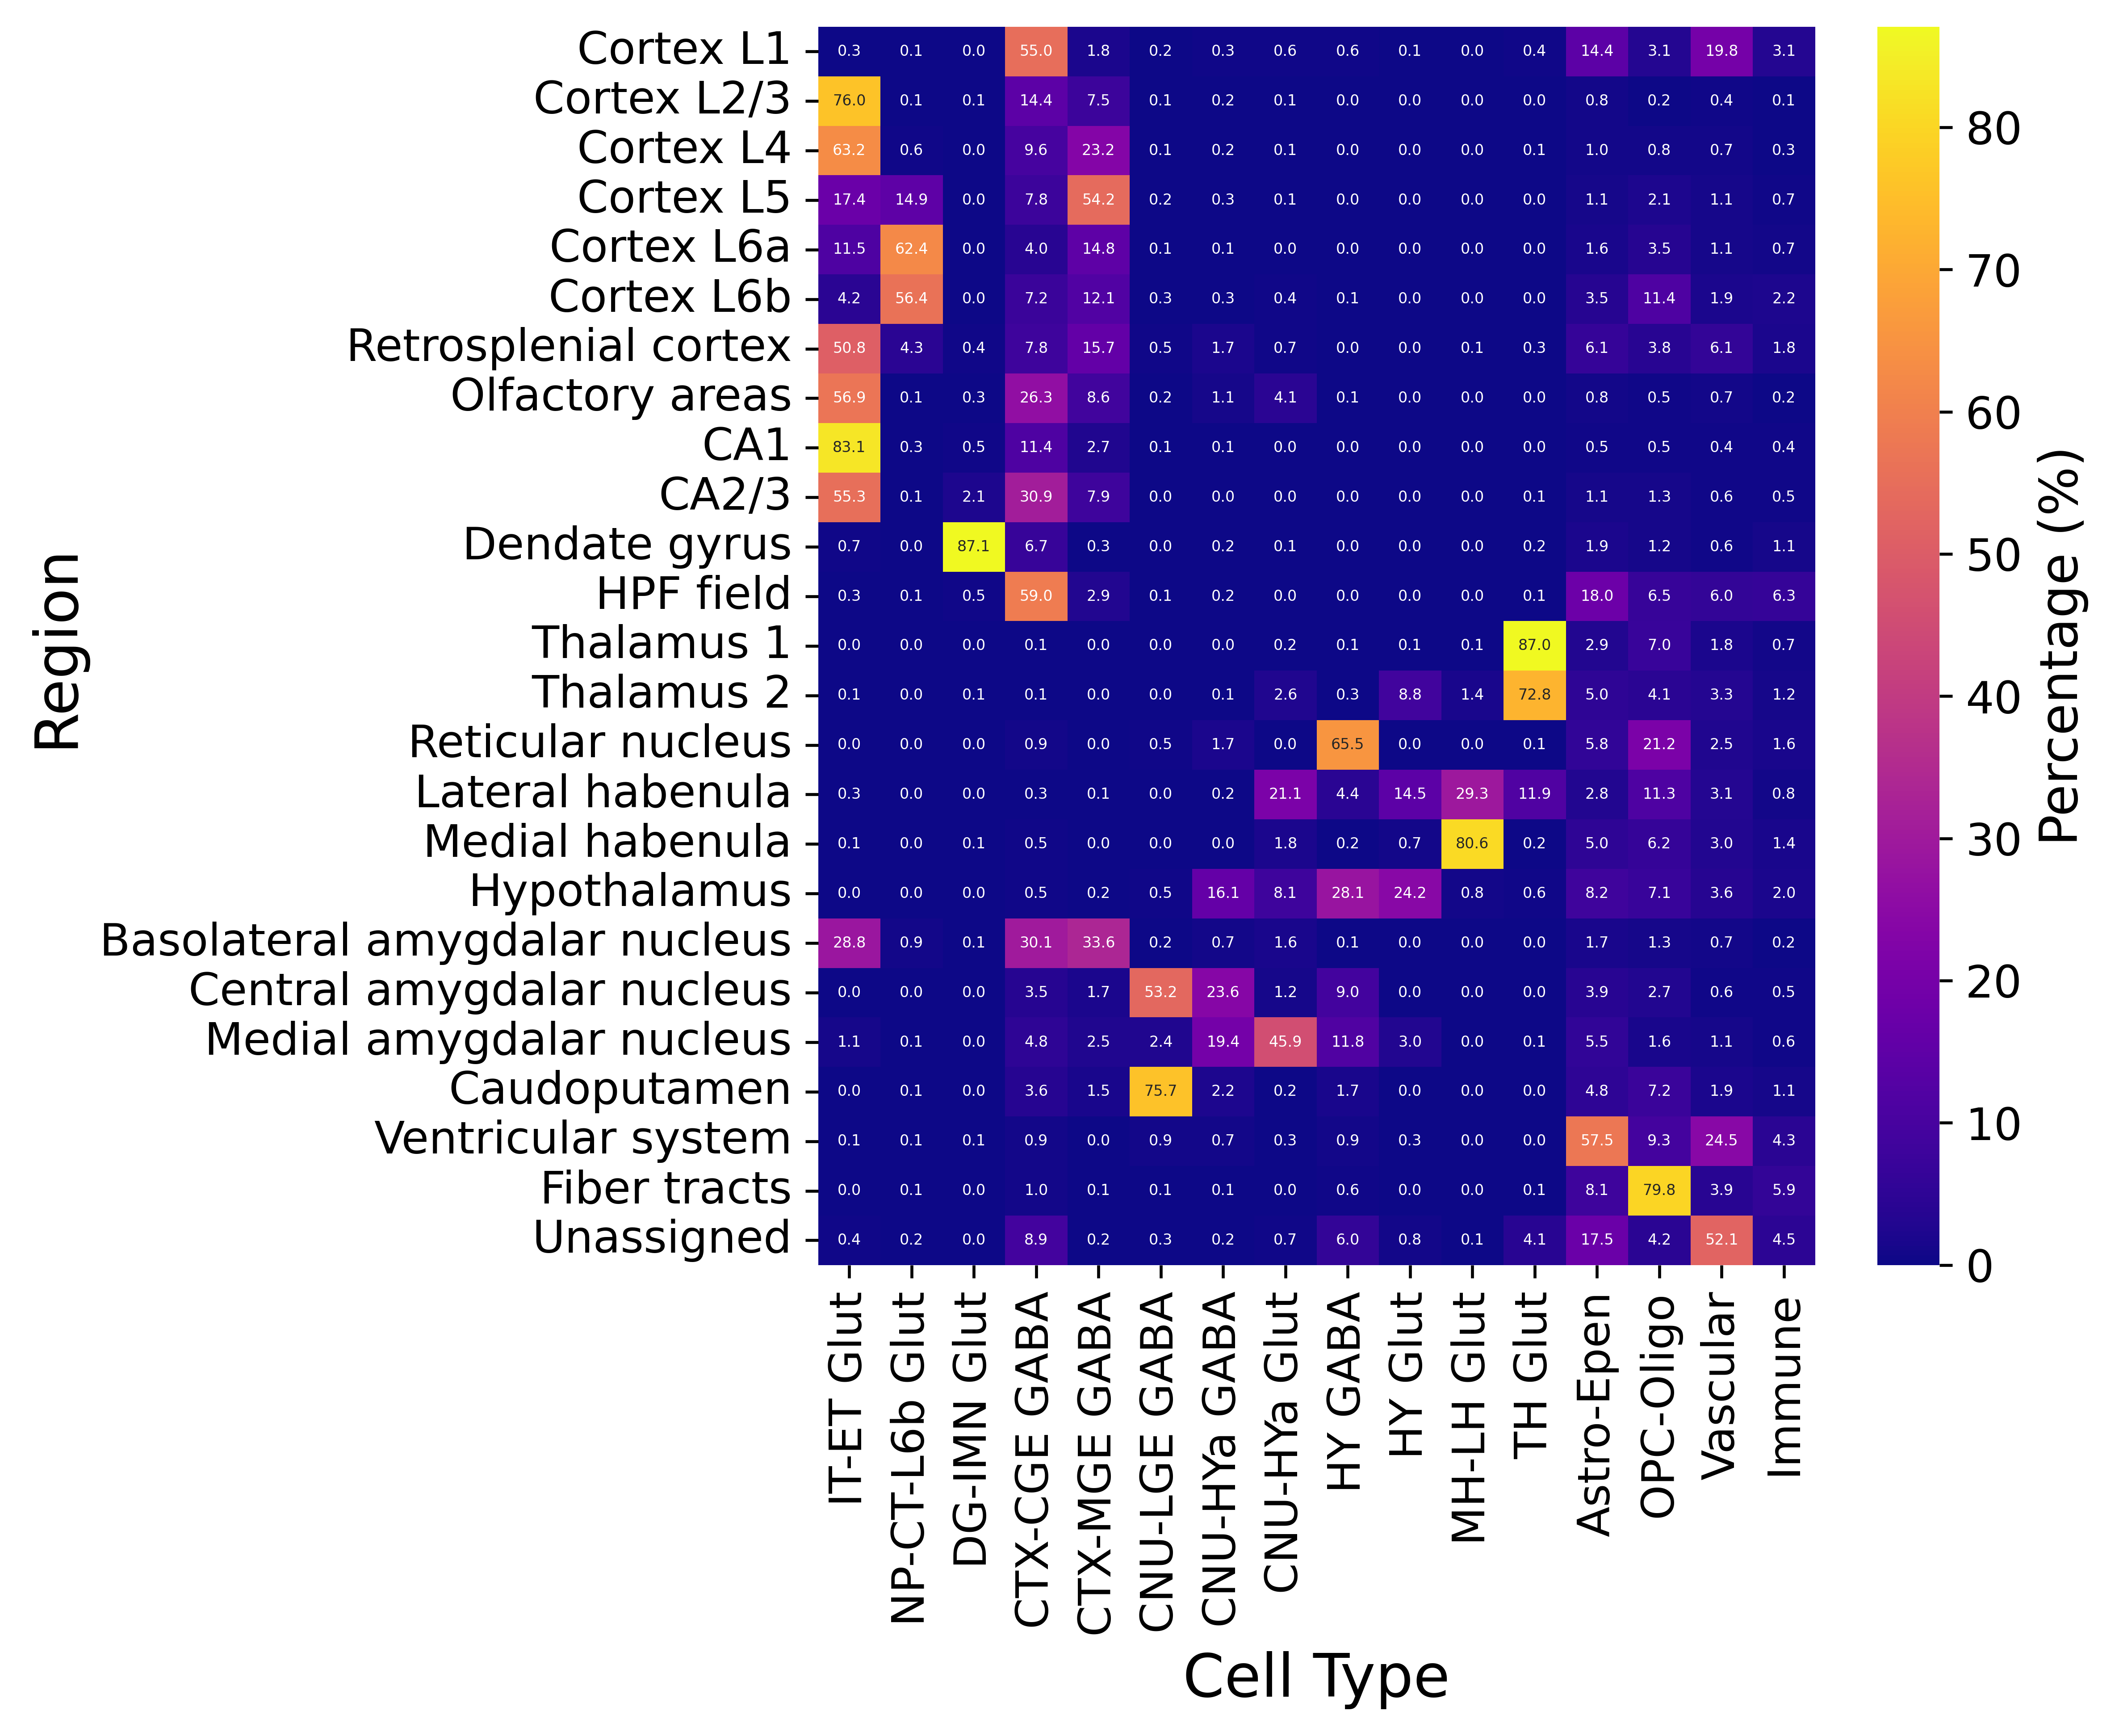

In [8]:
# Step 1: Get the count table
counts = pd.crosstab(adata.obs["Region"], adata.obs["Class"])

# Step 2: Convert to percentages (row-wise: per region)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# Step 3: Plot as heatmap
plt.figure(figsize=(6, 6))
ax = sns.heatmap(percentages, cmap="plasma", annot=True, fmt=".1f")


ax.set_xlabel("Cell Type", fontsize=16)
ax.set_ylabel("Region", fontsize=16)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

# Make colorbar label larger
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label("Percentage (%)", fontsize=14)

In [9]:
coexpr_df

,Region,Class,GroupA,GroupB,Coexpression_Both,Coexpression_Either,Only_A,Only_B,expressionA,expressionB,percent_A,percent_B,percent_coexpressed
0,Cortex L5,CTX-MGE GABA,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,980,4625,3209,436,4189,1416,69.383784,9.427027,21.189189
1,Cortex L5,IT-ET Glut,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,234,1376,1043,99,1277,333,75.799419,7.194767,17.005814
2,Cortex L5,CTX-CGE GABA,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,143,530,208,179,351,322,39.245283,33.773585,26.981132
3,Cortex L5,NP-CT-L6b Glut,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,138,1026,776,112,914,250,75.633528,10.916179,13.450292
4,Cortex L5,Astro-Epen,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,8,48,19,21,27,29,39.583333,43.750000,16.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,Medial habenula,CNU-HYa Glut,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,7,22,7,8,14,15,31.818182,36.363636,31.818182
353,Medial habenula,HY GABA,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,0,3,2,1,2,1,66.666667,33.333333,0.000000
354,Medial habenula,CNU-HYa GABA,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,0,1,1,0,1,0,100.000000,0.000000,0.000000
355,Medial habenula,DG-IMN Glut,Dp427c__Dp427m__Dp427p,Dp71_Dp40_firstexon__Dp40,0,0,0,0,0,0,NaN,NaN,NaN


In [31]:
original_percentage = coexpr_df.pivot_table(index=["Region"],columns=["Class"], values="percent_B")
original_percentage= original_percentage.reindex(index=adata.obs["Region"].astype("category").cat.categories,columns=adata.obs["Class"].astype("category").cat.categories)

heatmap_data_coexpression = coexpr_df.pivot_table(index=["Region"],columns=["Class"], values="Only_B")
heatmap_data_coexpression = heatmap_data_coexpression.reindex(index=adata.obs["Region"].astype("category").cat.categories,columns=adata.obs["Class"].astype("category").cat.categories)
heatmap_data_coexpression = heatmap_data_coexpression.fillna(0)

In [32]:
total_cells_per_region = counts.sum(axis=0)
threshold_per_region = total_cells_per_region * 0.005

In [33]:
mask = counts.gt(threshold_per_region, axis=1)

filtered_matrix_b = original_percentage.where(mask)
filtered_matrix_b = filtered_matrix_b.fillna(0)

In [34]:
filtered_matrix_c = filtered_matrix_b.where(heatmap_data_coexpression > 10)
filtered_matrix_c = filtered_matrix_c.fillna(0)

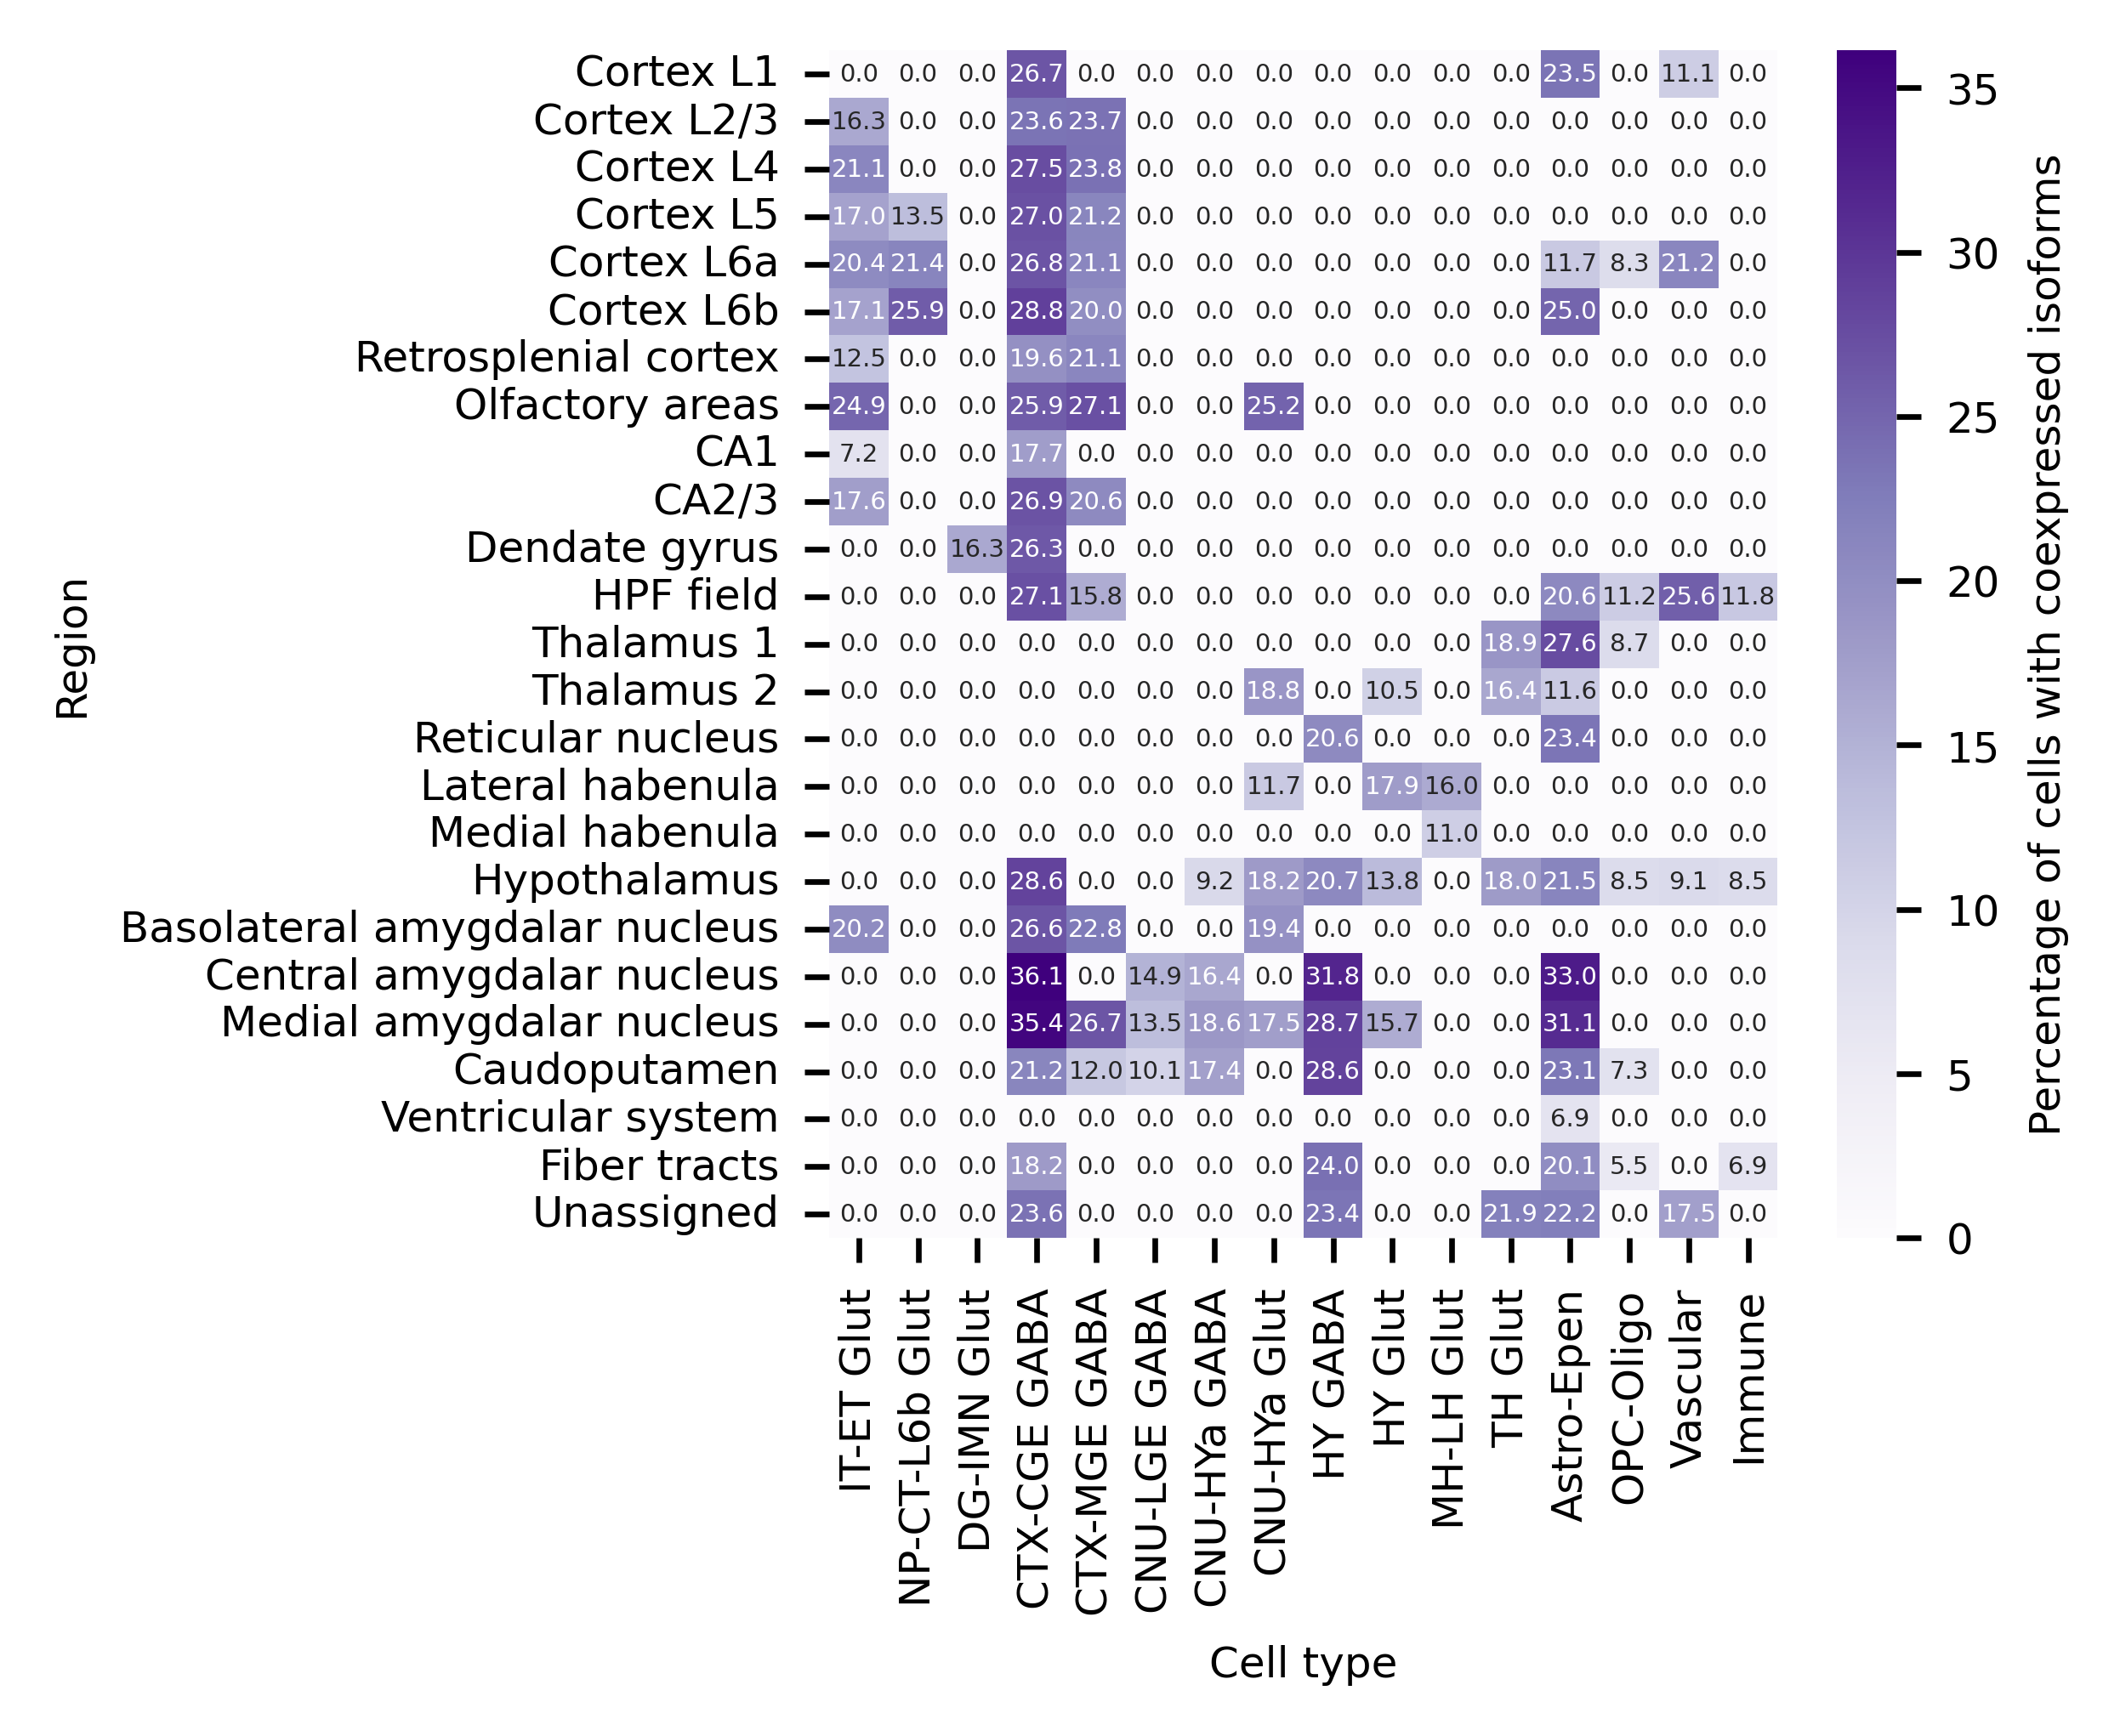

In [19]:
# Plot heatmap
mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 3.5,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
})



# Extract min and max values correctly
vmin = filtered_matrix_c.values.min()
vmax = filtered_matrix_c.values.max()


plt.figure(figsize=(3.96, 3.31))

sns.heatmap(filtered_matrix_c, annot=True, cmap="Purples", fmt=".1f",cbar_kws={'label': 'Percentage of cells with coexpressed isoforms'})
plt.xlabel("Cell type")
plt.ylabel("Region")

plt.tight_layout()
plt.savefig("/exports/humgen/qmao/Coexpression_isoforms.svg",format="svg",dpi=300, bbox_inches='tight')
plt.savefig("/exports/humgen/qmao/Coexpression_isoforms.tiff",format="tiff",dpi=300, bbox_inches='tight')
plt.show()




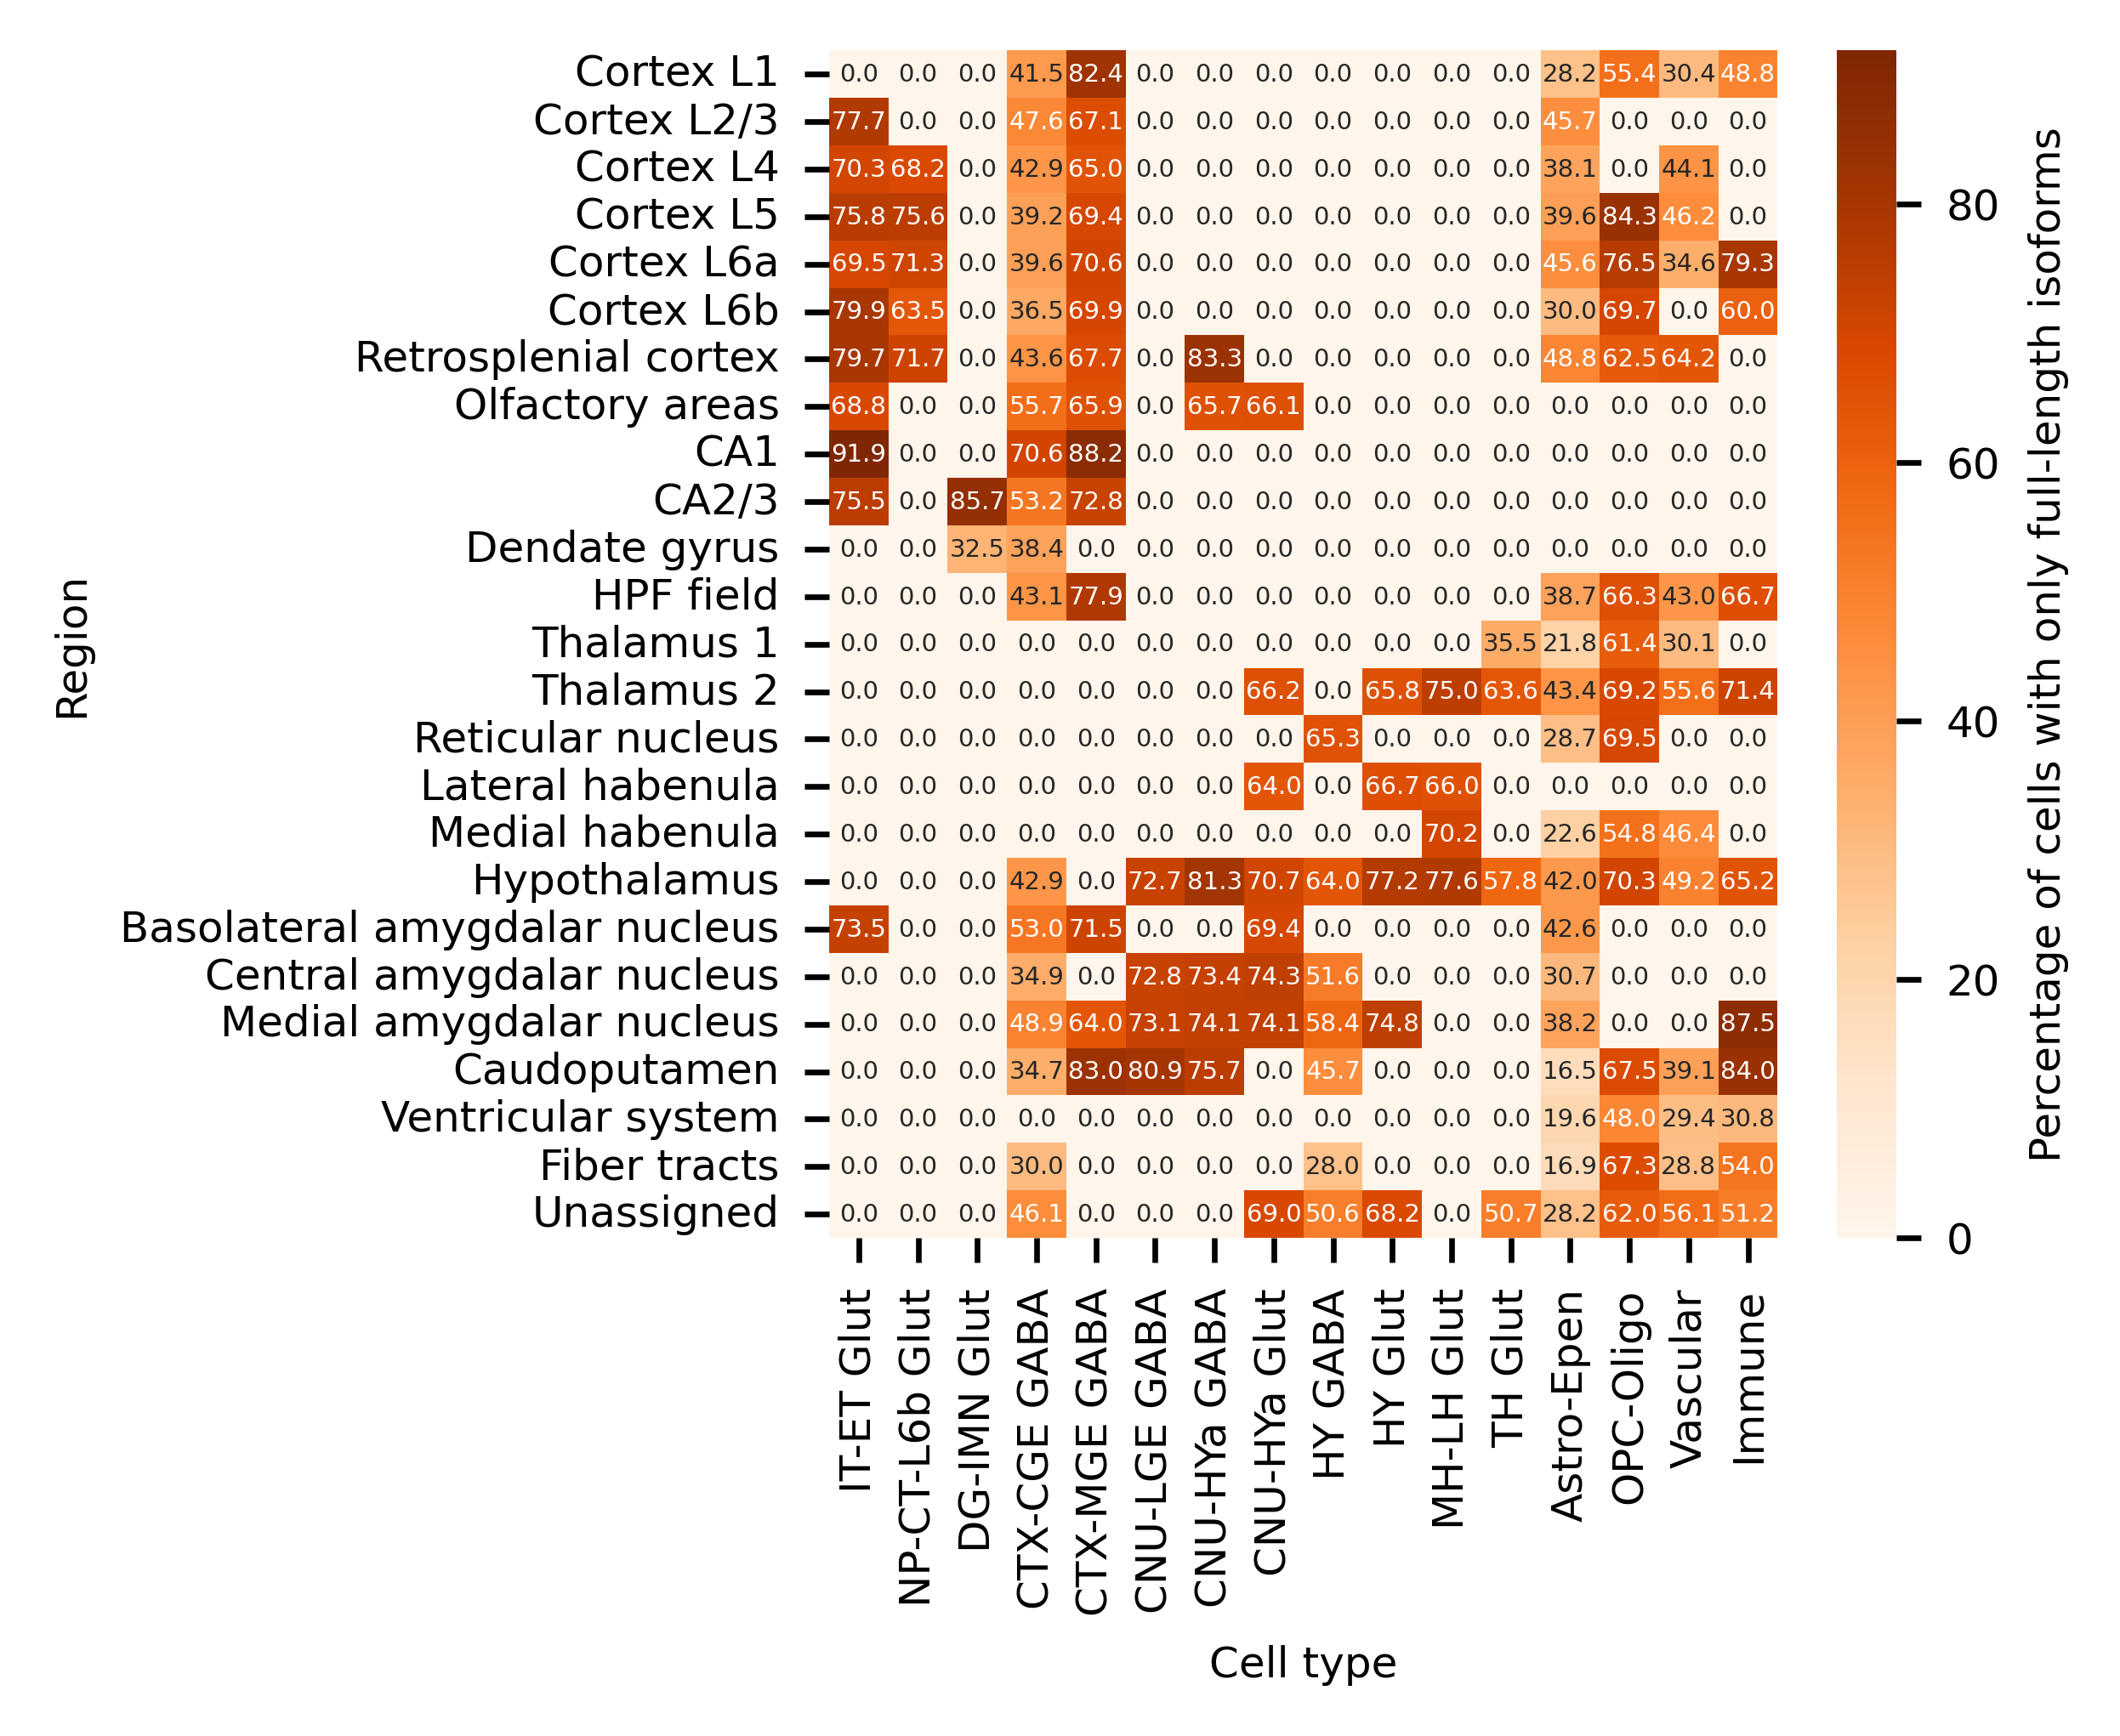

In [30]:
from matplotlib.colors import LinearSegmentedColormap

# Create yellow-only colormap (white → yellow)
yellow_cmap = LinearSegmentedColormap.from_list("custom_yellow", ["white", "yellow"])


#Plot heatmap
mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 3.5,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
})



# Extract min and max values correctly
vmin = filtered_matrix_c.values.min()
vmax = filtered_matrix_c.values.max()


plt.figure(figsize=(3.96, 3.31))

sns.heatmap(filtered_matrix_c, annot=True, cmap="Oranges", fmt=".1f",cbar_kws={'label': 'Percentage of cells with only full-length isoforms'})
plt.xlabel("Cell type")
plt.ylabel("Region")

plt.tight_layout()
plt.savefig("/exports/humgen/qmao/long_isoforms.svg",format="svg",dpi=300, bbox_inches='tight')
plt.savefig("/exports/humgen/qmao/long_isoforms.tiff",format="tiff",dpi=300, bbox_inches='tight')
plt.show()

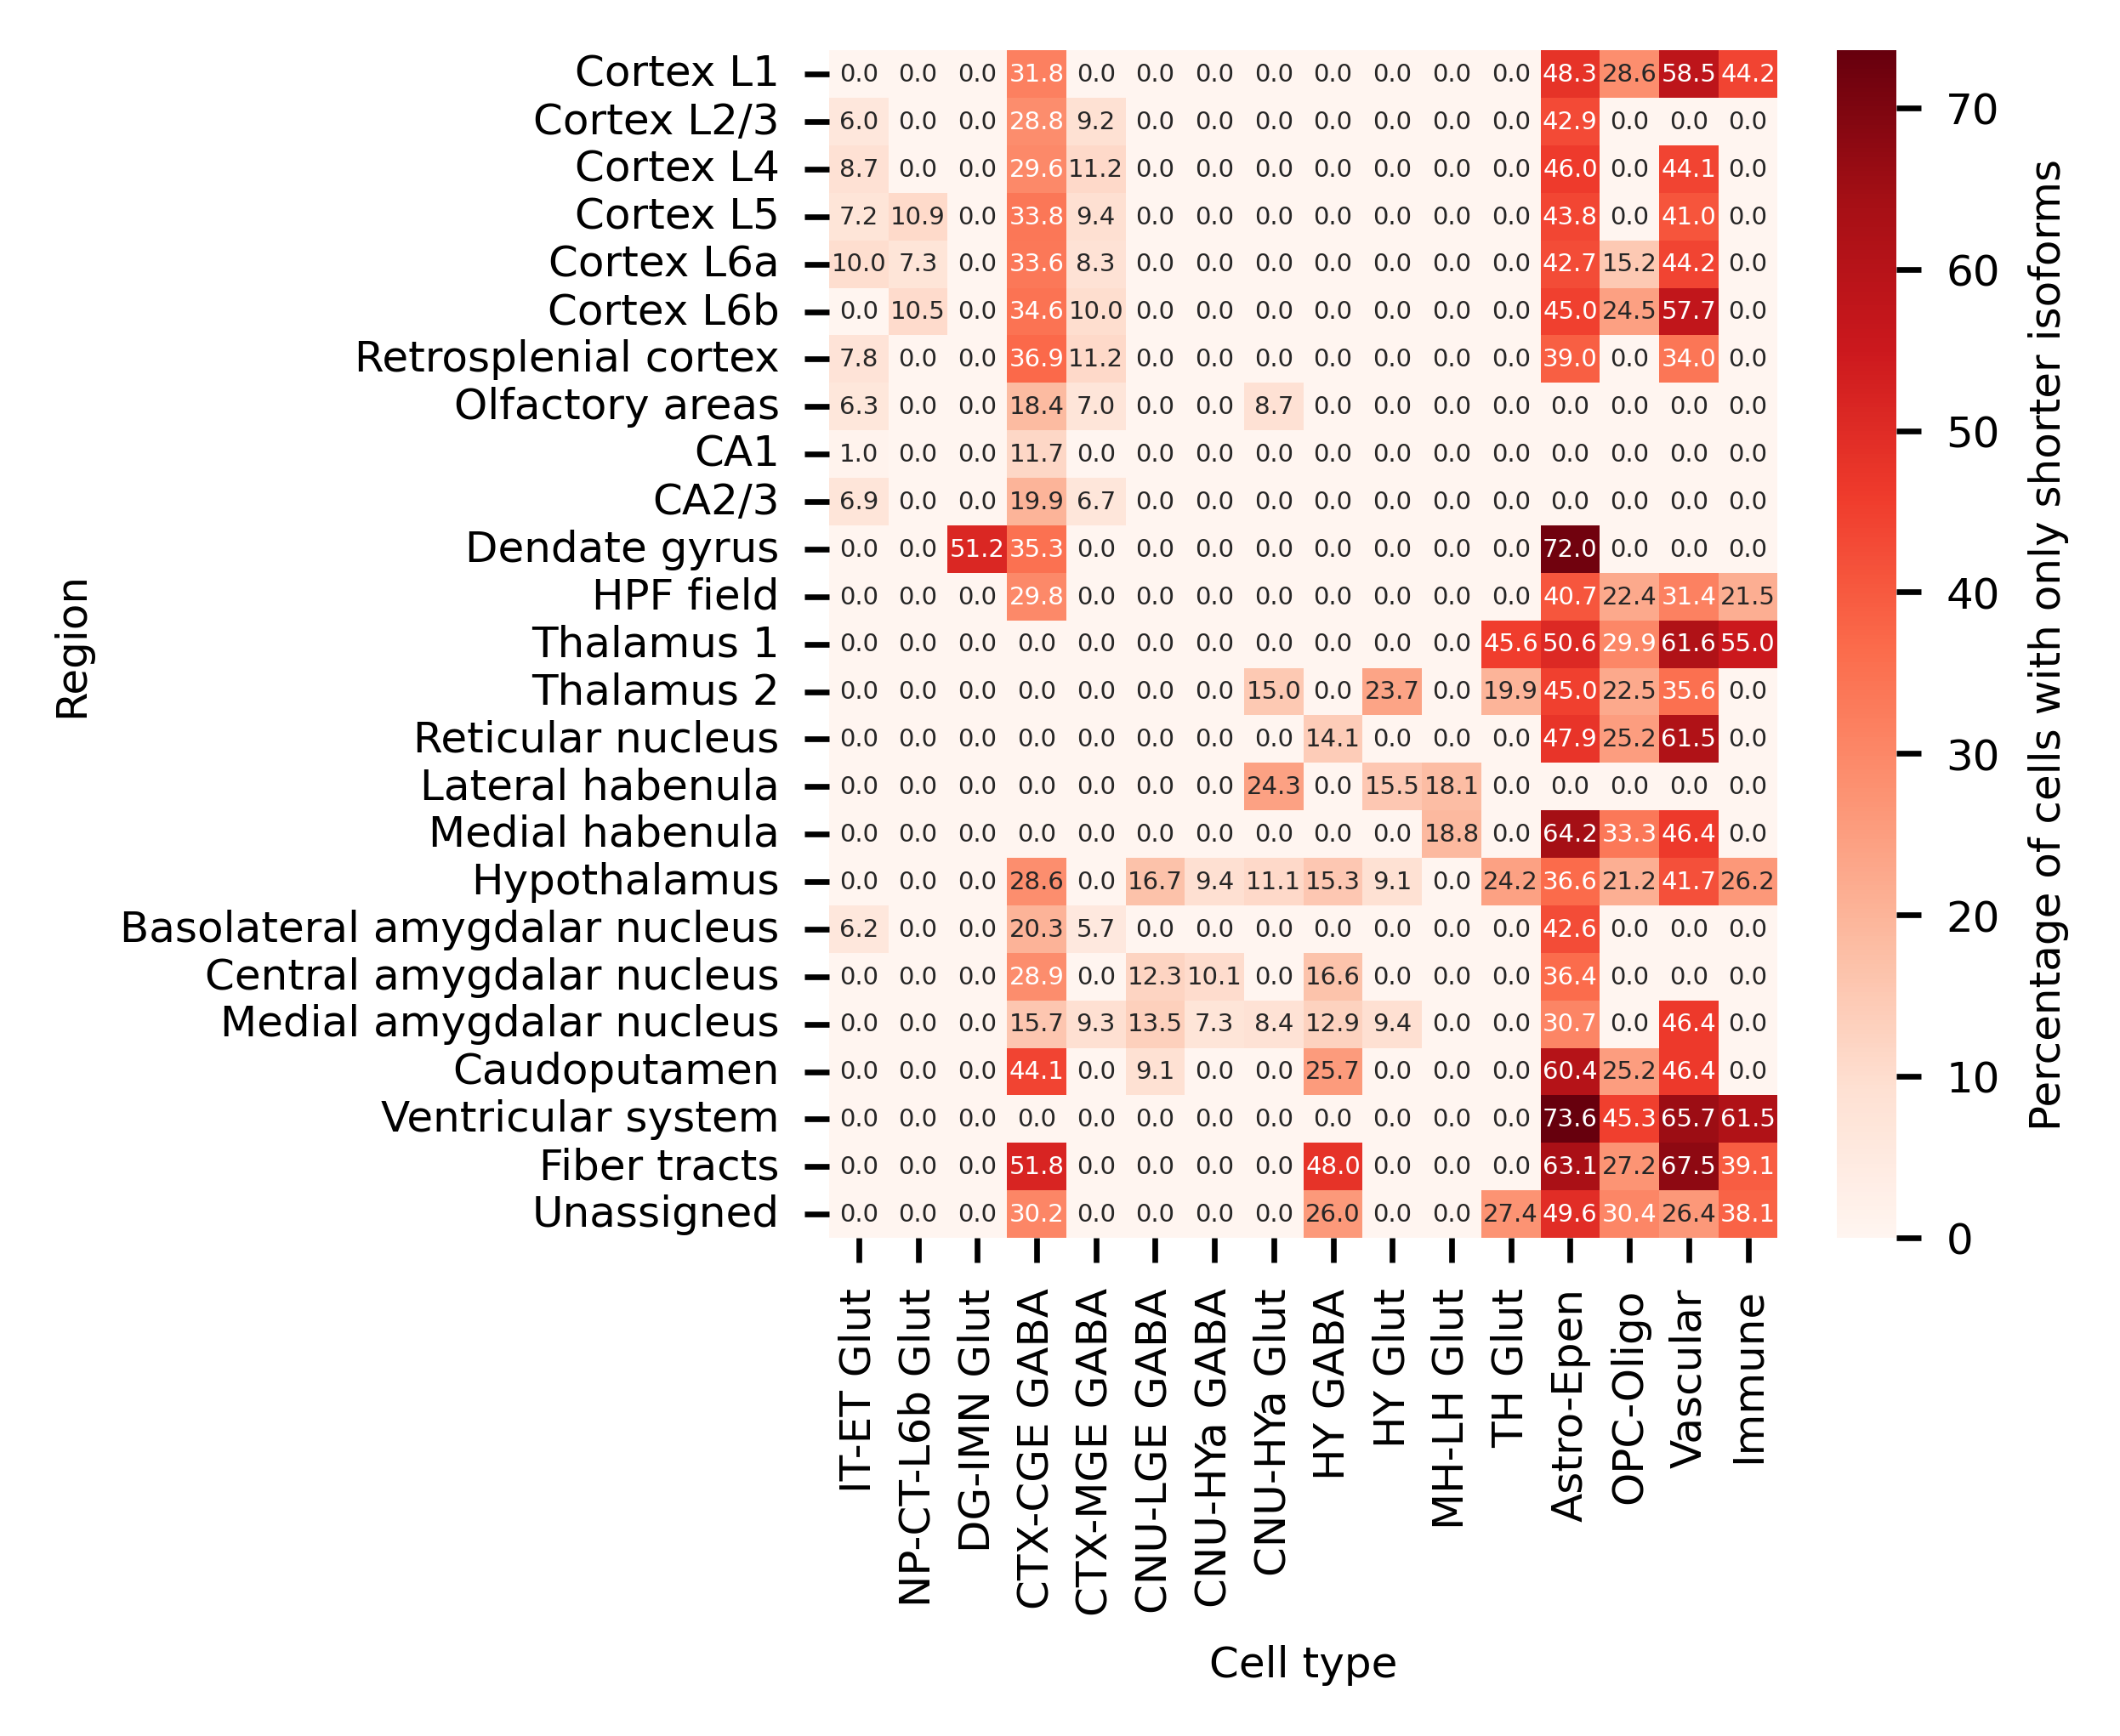

In [35]:
# Plot heatmap
mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 3.5,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
})



# Extract min and max values correctly
vmin = filtered_matrix_c.values.min()
vmax = filtered_matrix_c.values.max()


plt.figure(figsize=(3.96, 3.31))

sns.heatmap(filtered_matrix_c, annot=True, cmap="Reds", fmt=".1f",cbar_kws={'label': 'Percentage of cells with only shorter isoforms'})
plt.xlabel("Cell type")
plt.ylabel("Region")

plt.tight_layout()
plt.savefig("/exports/humgen/qmao/short_isoforms.svg",format="svg",dpi=300, bbox_inches='tight')
plt.savefig("/exports/humgen/qmao/short_isoforms.tiff",format="tiff",dpi=300, bbox_inches='tight')
plt.show()